# 14 안정화한 팀 모델 B의 처음 듣는 단어

13에서 팀 모델 B의 학습 설정을 **EMA(감쇠 0.999), 학습률 1e-3 고정, 30에폭, 마지막 에폭 모델**(E31)로 골랐습니다. 이 설정이 검증 F1(0.9461)뿐 아니라 **처음 듣는 단어 오작동**도 줄이는지 확인합니다. 09에서 이전 설정(20에폭, 학습률 고정, EMA 없음, 최고 에폭)은 약 18%였습니다(E16: 18.09% ± 6.80%).

| 번호 | 설정 | 학습 데이터 |
|---|---|---|
| E32 | EMA, 30에폭, 학습률 고정, **마지막 에폭** 모델 | 09와 같은 4묶음: 묶음마다 "명령 아님" 단어 5개를 학습에서 빼고, 남은 15개 단어는 녹음 전부 |
| E16r | 09의 E16 다시 실행: 20에폭, 학습률 고정, EMA 없음, 최고 에폭(뺀 단어를 제외한 검증 F1) | 같음 |

- 4묶음, 묶음 구성, 검증 묶음, 지표 계산은 09와 같습니다. 시드 2개. E16r은 같은 기기에서 비교하려고 넣었습니다(`RUN_BASELINE = False`면 건너뜀).
- 지표: 뺀 단어(처음 듣는 단어 흉내) 오작동, 남은 단어(들은 단어) 오작동, 잡음 오작동, 놓침, 명령 혼동, 매크로 F1(뺀 단어 제외 검증). E32는 마지막 에폭과 최고 에폭을 둘 다 적습니다.
- 단어별로 처음 들을 때 샌 비율을 09의 CNN(E16), 10의 Whisper + Linear(E19)와 나란히 비교합니다.
- 예상 시간: E32 8번 × 30에폭 + E16r 8번 × 20에폭, Kaggle T4 실측 에폭당 약 7.4초(학습 데이터가 4분의 3 조금 넘음)로 어림하면 약 50분.
- 시험 묶음은 쓰지 않습니다.

In [5]:
# 셀 1. 설정과 버전
import os, sys, time, random, copy, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import matplotlib.pyplot as plt

SMOKE = False                  # True: 단어마다 몇 개만, 짧게 (결과 숫자는 쓰지 않음)
USE_DRIVE = False              # True: Colab에서 Google Drive를 연결해 스펙트로그램을 Drive에 저장·재사용 (10·11에서 저장한 것 사용)
SEEDS = [0, 1]
RUNS_SPEC = {                  # 번호: (에폭, 학습률 스케줄, EMA)
    "E32": (30, "고정", True),     # 13에서 고른 B 설정(E31): EMA, 학습률 고정, 30에폭, 마지막 에폭 모델
    "E16r": (20, "고정", False),   # 09의 E16 설정 다시 실행 (같은 기기에서 비교하려고)
}
RUN_BASELINE = True            # False면 E16r을 건너뜀 (약 19분 절약, 대신 09의 Colab 결과와 비교)
EMA_DECAY = 0.999
CONDS = {"E15": 153, "E16": None}   # 셀 2(09와 같은 코드)가 출력에 씀
FOLD_SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
AUX = ["bed", "bird", "cat", "dog", "happy", "house", "marvin", "sheila", "tree", "wow"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256          # 09와 같음 (에폭은 실험마다 RUNS_SPEC으로 바꿈)
B_CHANNELS = [16, 32, 64, 128]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
if SMOKE:
    CONDS = {"E15": 3, "E16": None}
    RUNS_SPEC = {k: (max(2, e // 10), s, m) for k, (e, s, m) in RUNS_SPEC.items()}
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)

python 3.13.16 | torch 2.11.0+cu130 | torchaudio 2.11.0+cu130 | pandas 2.3.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 cache


In [6]:
# 셀 2. 데이터 (08·09와 같은 구성. 4묶음은 여기서 쓰지 않음)
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 쓰지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert sorted(pool.word.unique()) == sorted(DIGITS + AUX)
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서: 07에서 쓴 153개가 먼저
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()

rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group", "word"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
TRAIN_WORD = train_all.word.to_numpy(copy=True)
VAL_WORD = val.word.to_numpy(copy=True)

# 단어 4묶음: 숫자 3·3·2·2개 + 보조 단어 2·2·3·3개
fr = np.random.default_rng(FOLD_SEED)
d, a = list(fr.permutation(DIGITS)), list(fr.permutation(AUX))
FOLDS, i_d, i_a = [], 0, 0
for nd, na in [(3, 2), (3, 2), (2, 3), (2, 3)]:
    FOLDS.append([str(w) for w in sorted(d[i_d:i_d + nd]) + sorted(a[i_a:i_a + na])])
    i_d += nd; i_a += na
assert sorted(sum(FOLDS, [])) == sorted(DIGITS + AUX)

def train_mask(n, held):
    keep_n = (train_all.group != "seen_other") | (n is None) | (train_all["rank"] < (n or 0))
    return (keep_n & ~train_all.word.isin(held)).to_numpy(copy=True)

for f, held in enumerate(FOLDS):
    print(f"묶음 {f + 1}: 학습에서 뺄 단어 {held}")
    for eid, n in CONDS.items():
        m = train_mask(n, held)
        k = int((Y_ALL[torch.from_numpy(m)] == L2I[OTHER]).sum())
        print(f"   {eid} (단어마다 {n if n else '전부'}): 학습 {m.sum():,}개, '명령 아님' {k:,}개 ({k / m.sum():.1%}), "
              f"검증에서 뺀 단어 {np.isin(VAL_WORD, held).sum():,}개")

묶음 1: 학습에서 뺄 단어 ['four', 'six', 'two', 'cat', 'wow']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,469개
   E16 (단어마다 전부): 학습 66,857개, '명령 아님' 36,088개 (54.0%), 검증에서 뺀 단어 1,469개
묶음 2: 학습에서 뺄 단어 ['five', 'seven', 'three', 'dog', 'marvin']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,502개
   E16 (단어마다 전부): 학습 66,560개, '명령 아님' 35,791개 (53.8%), 검증에서 뺀 단어 1,502개
묶음 3: 학습에서 뺄 단어 ['nine', 'zero', 'bed', 'happy', 'tree']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,331개
   E16 (단어마다 전부): 학습 68,339개, '명령 아님' 37,570개 (55.0%), 검증에서 뺀 단어 1,331개
묶음 4: 학습에서 뺄 단어 ['eight', 'one', 'bird', 'house', 'sheila']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,278개
   E16 (단어마다 전부): 학습 68,189개, '명령 아님' 37,420개 (54.9%), 검증에서 뺀 단어 1,278개


In [7]:
# 셀 3. 소리 읽기 → 로그 멜 (07·08과 같은 설정, 저장해 두고 다시 씀)
def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

def spec(df, name):
    def run():
        M, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=256, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

MEL_ALL = spec(train_all, "spec08_train_pool")["mel"]           # 08과 같은 이름·순서 → 저장된 게 있으면 다시 씀
MEL_VAL = spec(val, "spec09_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

  spec08_train_pool: 저장된 것 사용 (처음 계산 25초)
  spec11_val: 저장된 것 사용 (처음 계산 3초)


In [8]:
# 셀 4. 평가 함수와 팀 모델 B (08과 같은 CNN·학습, 에폭 선택만 뺀 단어 제외)
def evaluate(pred, held):
    """held: 학습에서 뺀 단어. 지표를 뺀 단어 / 남은 단어 / 잡음으로 나눠 계산"""
    p, t = pred.cpu().numpy(), Y_VAL.numpy()
    oth = L2I[OTHER]
    is_held = np.isin(VAL_WORD, held)
    sel = ~is_held                                           # 에폭 선택용: 뺀 단어 제외
    cm = np.bincount(t[sel] * K + p[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    is_cmd = t != oth
    known = (val.group.values == "seen_other") & ~is_held
    noise = val.group.values == "noise"
    return {"f1": float(f1.mean()), "acc": float(tp.sum() / cm.sum()),
            "fa_held": float(np.mean(p[is_held] != oth)) if is_held.any() else float("nan"),
            "fa_known": float(np.mean(p[known] != oth)),
            "fa_noise": float(np.mean(p[noise] != oth)) if noise.any() else float("nan"),
            "miss": float(np.mean(p[is_cmd] == oth)),
            "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd]))),
            "pred": p}

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def train_cnn(mask, seed, held):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, hist, t_start = None, [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx)
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred, held)
        hist.append({"loss": tot / len(Xtr), "f1": r["f1"], "fa_held": r["fa_held"], "fa_known": r["fa_known"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["sec"] = time.time() - t_start
    return best, pd.DataFrame(hist)

In [9]:
# 셀 5. 학습 함수: 12·13과 같은 학습(EMA 선택), 학습 데이터와 뺀 단어를 받음. 에폭마다 뺀 단어 오작동도 남김
def train_fold(mask, held, seed, epochs, ema, tag):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    ema_model = AveragedModel(cnn, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True) if ema else None
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best, t_start = [], None, time.time()
    for ep in range(epochs):
        cnn.train(); t0 = time.time()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if ema_model is not None:
                ema_model.update_parameters(cnn)
        model = ema_model if ema_model is not None else cnn
        model.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([model(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred, held)
        hist.append({"epoch": ep + 1, "f1": r["f1"], "fa_held": r["fa_held"], "fa_known": r["fa_known"], "miss": r["miss"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
        if (ep + 1) % 10 == 0 or ep + 1 == epochs:
            print(f"    [{tag} 시드 {seed}] 에폭 {ep + 1:2d}/{epochs} | F1 {r['f1']:.4f} | 오작동 뺀 단어 {r['fa_held']:.2%} · 남은 단어 {r['fa_known']:.2%} | "
                  f"놓침 {r['miss']:.2%} | {time.time() - t_start:.0f}초 경과")
    last = {**r, "epoch": epochs}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    return best, last, pd.DataFrame(hist)

In [10]:
# 셀 6. 학습: 4묶음 × 시드 2개 (E32), 그리고 E16r (매번 처음부터)
RUNS = []
t_all = time.time()
for eid, (epochs, sched, ema) in RUNS_SPEC.items():
    if eid == "E16r" and not RUN_BASELINE:
        continue
    for f, held in enumerate(FOLDS):
        mask = train_mask(None, held)
        for seed in SEEDS:
            print(f"{eid} 묶음 {f + 1} 시드 {seed} 시작 (학습 {mask.sum():,}개, 전체 {time.time() - t_all:.0f}초 경과)")
            best, last, h = train_fold(mask, held, seed, epochs, ema, f"{eid} 묶음 {f + 1}")
            use = last if eid == "E32" else best                     # E32는 마지막 에폭, E16r은 09처럼 최고 에폭
            RUNS.append({"번호": eid, "묶음": f + 1, "시드": seed, "held": held, "use": use, "best": best, "last": last, "hist": h,
                         "평가 에폭": use["epoch"], "에폭당 초": h.sec.mean()})
            print(f"  → {'마지막' if eid == 'E32' else '최고'} 에폭({use['epoch']}): F1 {use['f1']:.4f} | 오작동 뺀 단어 {use['fa_held']:.2%} · "
                  f"남은 단어 {use['fa_known']:.2%} · 잡음 {use['fa_noise']:.2%} | 놓침 {use['miss']:.2%} | 에폭당 {h.sec.mean():.1f}초")
print(f"전체 {time.time() - t_all:.0f}초")

E32 묶음 1 시드 0 시작 (학습 66,857개, 전체 0초 경과)
    [E32 묶음 1 시드 0] 에폭 10/30 | F1 0.8053 | 오작동 뺀 단어 5.79% · 남은 단어 2.02% | 놓침 17.77% | 68초 경과
    [E32 묶음 1 시드 0] 에폭 20/30 | F1 0.9481 | 오작동 뺀 단어 13.68% · 남은 단어 1.41% | 놓침 4.43% | 136초 경과
    [E32 묶음 1 시드 0] 에폭 30/30 | F1 0.9502 | 오작동 뺀 단어 14.91% · 남은 단어 1.53% | 놓침 4.00% | 203초 경과
  → 마지막 에폭(30): F1 0.9502 | 오작동 뺀 단어 14.91% · 남은 단어 1.53% · 잡음 0.00% | 놓침 4.00% | 에폭당 6.8초
E32 묶음 1 시드 1 시작 (학습 66,857개, 전체 210초 경과)
    [E32 묶음 1 시드 1] 에폭 10/30 | F1 0.4557 | 오작동 뺀 단어 9.67% · 남은 단어 7.13% | 놓침 42.43% | 67초 경과
    [E32 묶음 1 시드 1] 에폭 20/30 | F1 0.9438 | 오작동 뺀 단어 13.55% · 남은 단어 1.44% | 놓침 4.29% | 135초 경과
    [E32 묶음 1 시드 1] 에폭 30/30 | F1 0.9480 | 오작동 뺀 단어 14.84% · 남은 단어 1.51% | 놓침 3.75% | 202초 경과
  → 마지막 에폭(30): F1 0.9480 | 오작동 뺀 단어 14.84% · 남은 단어 1.51% · 잡음 0.85% | 놓침 3.75% | 에폭당 6.7초
E32 묶음 2 시드 0 시작 (학습 66,560개, 전체 416초 경과)
    [E32 묶음 2 시드 0] 에폭 10/30 | F1 0.7898 | 오작동 뺀 단어 9.65% · 남은 단어 1.18% | 놓침 22.17% | 67초 경과
    [E32 묶음 2 시드 0] 에폭 20/30 | F1 0.948

In [11]:
# 셀 7. 결과 표: 실험마다 4묶음 × 시드 2개 = 8번의 평균 ± 표준편차 (뺀 단어 오작동은 8번 사이 표준편차)
pd.set_option("display.width", 230)
cols = [("f1", "매크로 F1"), ("fa_held", "오작동(뺀 단어)"), ("fa_known", "오작동(남은 단어)"), ("fa_noise", "오작동(잡음)"), ("miss", "놓침"), ("confuse", "명령 혼동")]
def summarize(runs, key):
    d = pd.DataFrame([{c: r[key][c] for c, _ in cols} for r in runs])
    return {name: (f"{d[c].mean():.4f} ± {d[c].std():.4f}" if c == "f1" else f"{d[c].mean():.2%} ± {d[c].std():.2%}") for c, name in cols}
rows = []
for eid in RUNS_SPEC:
    runs = [r for r in RUNS if r["번호"] == eid]
    if not runs:
        continue
    if eid == "E32":
        rows.append({"번호": "E32 (마지막 에폭)", **summarize(runs, "last")})
        rows.append({"번호": "E32 (최고 에폭, 참고)", **summarize(runs, "best")})
    else:
        rows.append({"번호": "E16r (최고 에폭)", **summarize(runs, "best")})
print(pd.DataFrame(rows).to_string(index=False))
print("\n묶음별 뺀 단어 오작동 (시드 평균):")
for eid in RUNS_SPEC:
    runs = [r for r in RUNS if r["번호"] == eid]
    if runs:
        print(f"  {eid}: " + " | ".join(f"묶음 {f + 1} {np.mean([r['use']['fa_held'] for r in runs if r['묶음'] == f + 1]):.2%}" for f in range(len(FOLDS))))
print("\n참고 (09·10 결과에서 옮김, 같은 4묶음): CNN E16 뺀 단어 18.09% ± 6.80%, 남은 단어 2.50%, 놓침 5.47%, F1 0.9229 (Colab T4) / "
      "Whisper + Linear E19 31.83% ± 11.51%, 남은 단어 0.69%, 놓침 1.76%, F1 0.9780")
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 시드 {SEEDS} | 검증 {len(val):,}개")

             번호          매크로 F1      오작동(뺀 단어)    오작동(남은 단어)       오작동(잡음)            놓침         명령 혼동
   E32 (마지막 에폭) 0.9488 ± 0.0017 16.39% ± 3.59% 1.47% ± 0.15% 0.11% ± 0.30% 3.96% ± 0.23% 2.51% ± 0.15%
E32 (최고 에폭, 참고) 0.9498 ± 0.0018 16.26% ± 3.61% 1.45% ± 0.15% 0.11% ± 0.30% 3.98% ± 0.22% 2.41% ± 0.13%
   E16r (최고 에폭) 0.9233 ± 0.0046 16.81% ± 7.01% 2.38% ± 1.52% 0.43% ± 0.79% 5.83% ± 2.06% 3.65% ± 0.36%

묶음별 뺀 단어 오작동 (시드 평균):
  E32: 묶음 1 14.87% | 묶음 2 16.31% | 묶음 3 21.68% | 묶음 4 12.72%
  E16r: 묶음 1 16.24% | 묶음 2 10.69% | 묶음 3 25.28% | 묶음 4 15.02%

참고 (09·10 결과에서 옮김, 같은 4묶음): CNN E16 뺀 단어 18.09% ± 6.80%, 남은 단어 2.50%, 놓침 5.47%, F1 0.9229 (Colab T4) / Whisper + Linear E19 31.83% ± 11.51%, 남은 단어 0.69%, 놓침 1.76%, F1 0.9780
device cuda | 시드 [0, 1] | 검증 9,400개


    단어   E32  E16r  CNN E16 (09)  Whisper E19 (10)                     E32에서 많이 간 명령
  nine 54.4% 64.6%         64.6%             65.3% no 20.5%, down 15.7%, right 13.8%
   dog 76.1% 47.0%         62.9%             86.0%   down 48.7%, go 17.0%, stop 8.6%
   cat 34.4% 36.1%         36.1%             23.3%     left 9.4%, up 9.4%, stop 5.8%
   two 22.3% 28.6%         28.5%             24.3%      go 14.8%, no 5.2%, down 1.0%
 house 18.2% 21.0%         23.8%             91.3%       off 6.7%, no 5.9%, yes 1.8%
   one 21.2% 26.6%         23.6%             72.1%   on 13.5%, right 5.1%, left 2.1%
 eight 13.2% 13.2%         19.4%             52.6%      up 4.9%, on 3.6%, right 2.9%
  zero 16.8% 17.4%         17.4%             43.4%       no 12.4%, go 1.8%, yes 1.6%
  four 10.9% 11.7%         11.7%             26.4%        on 4.4%, go 3.4%, off 2.9%
   wow 17.6% 11.7%         11.7%             66.8%       no 6.7%, down 2.8%, go 2.6%
  five 17.4% 16.3%         11.6%             34.1%      on 9.0%, 

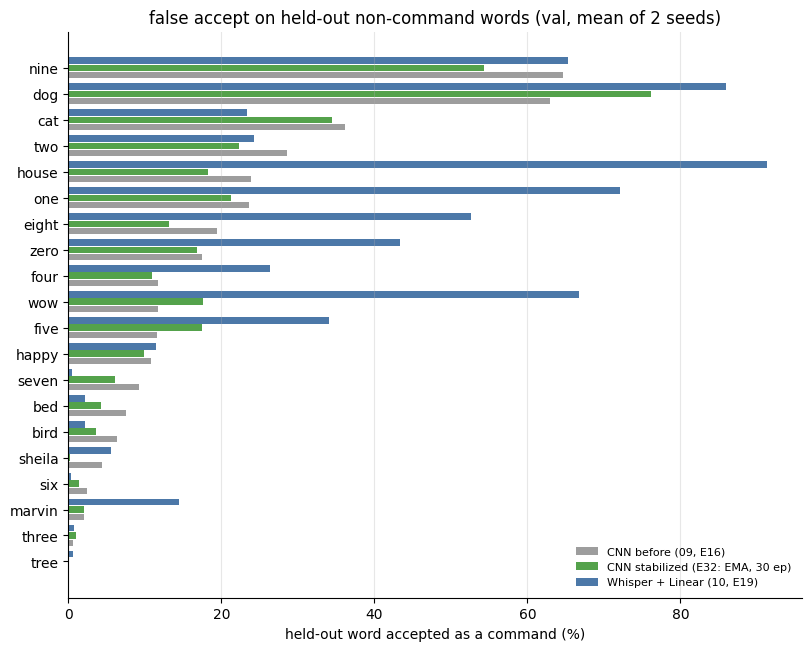

In [12]:
# 셀 8. 단어마다: 처음 들을 때 명령으로 샌 비율 (시드 2개 평균), 09의 CNN(E16)·10의 Whisper(E19)와 나란히, 그리고 E32에서 많이 간 명령
# 09·10 값은 각 결과 노트북의 단어별 표에서 옮김
CNN_E16 = {"nine": .6461, "dog": .6294, "cat": .3611, "two": .2855, "house": .2385, "one": .2365, "eight": .1936, "zero": .1745, "four": .1166, "wow": .1166,
           "five": .1158, "happy": .1073, "seven": .0917, "bed": .0751, "bird": .0632, "sheila": .0441, "six": .0238, "marvin": .0205, "three": .0056, "tree": .0000}
WH_E19 = {"nine": .653, "dog": .860, "cat": .233, "two": .243, "house": .913, "one": .721, "eight": .526, "zero": .434, "four": .264, "wow": .668,
          "five": .341, "happy": .114, "seven": .004, "bed": .021, "bird": .022, "sheila": .056, "six": .003, "marvin": .144, "three": .007, "tree": .006}
WORDS = sorted(DIGITS + AUX)
oth = L2I[OTHER]
rows = []
for w in WORDS:
    mw = VAL_WORD == w
    d = {"단어": w}
    for eid in RUNS_SPEC:
        runs = [r for r in RUNS if r["번호"] == eid and w in r["held"]]
        if runs:
            d[eid] = np.mean([np.mean(r["use"]["pred"][mw] != oth) for r in runs])
    runs = [r for r in RUNS if r["번호"] == "E32" and w in r["held"]]
    leak = np.concatenate([r["use"]["pred"][mw] for r in runs])
    leak = leak[leak != oth]
    top = pd.Series([LABELS[i] for i in leak]).value_counts()
    d["CNN E16 (09)"] = CNN_E16[w]; d["Whisper E19 (10)"] = WH_E19[w]
    d["E32에서 많이 간 명령"] = ", ".join(f"{k} {v / (mw.sum() * len(runs)):.1%}" for k, v in top.head(3).items()) or "-"
    rows.append(d)
wt = pd.DataFrame(rows).sort_values("CNN E16 (09)", ascending=False)
print(wt.to_string(index=False, float_format=lambda v: f"{v:.1%}"))

fig, ax = plt.subplots(figsize=(8, 6.4), constrained_layout=True)
order = wt.단어.values[::-1]
yy = np.arange(len(order)); hgt = 0.28
series = [("CNN E16 (09)", "#9D9D9D", "CNN before (09, E16)"), ("E32", "#54A24B", "CNN stabilized (E32: EMA, 30 ep)"), ("Whisper E19 (10)", "#4C78A8", "Whisper + Linear (10, E19)")]
for k, (col, c, lab) in enumerate(series):
    vals = wt.set_index("단어").loc[order, col].values * 100
    ax.barh(yy + (k - 1) * hgt, vals, height=hgt - 0.03, color=c, label=lab)
ax.set_yticks(yy); ax.set_yticklabels(order)
ax.set_xlabel("held-out word accepted as a command (%)")
ax.set_title("false accept on held-out non-command words (val, mean of 2 seeds)")
ax.grid(axis="x", alpha=.3); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="lower right", fontsize=8)
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/14_heldout_words.png", dpi=150)
plt.show()